# 03. Ewaluacja pipeline'u: retrieval → QA → synergia komponentów

Zbiór ewaluacyjny `data/eval/qa_eval.jsonl`: **40 pytań**, 37 o sklepie (odpowiedź w FAQ, tylko w dokumentach
albo w obu) oraz 3 poza zakresem. Każde pytanie ma listę źródeł wzorcowych i odpowiedź wzorcową.
Wyniki liczy `scripts/evaluate.py` (tu tylko wczytujemy i interpretujemy).

Metryki:
* **retrieval**: Recall@k (czy źródło wzorcowe jest w top-k) i MRR (średnia odwrotność pozycji pierwszego trafienia),
* **QA**: Token-F1 (Lab 3), ROUGE-L, BERTScore-F1 (Lab 4), **LLM-as-judge** (Gemma ocenia 1-5 *faithfulness*
 : ugruntowanie w źródłach, i *correctness*, zgodność z wzorcem), poprawność odmowy poza zakresem.

In [1]:
import pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, display
pd.set_option("display.max_colwidth", 160)
R = "../results"

## 1. Retrieval: metoda wyszukiwania i wpływ routingu klasyfikatorem

,metoda,routing,Recall@1,Recall@3,Recall@4,MRR,ms/zapytanie
0,tfidf,cała baza,0.595,0.811,0.811,0.713,0.262
1,tfidf,z filtrem kategorii,0.622,0.838,0.919,0.745,0.239
2,bm25,cała baza,0.622,0.865,0.919,0.758,0.092
3,bm25,z filtrem kategorii,0.703,0.919,0.973,0.811,0.089
4,dense,cała baza,0.811,0.919,0.973,0.878,67.789
5,dense,z filtrem kategorii,0.892,0.946,0.973,0.921,11.230
6,hybrid,cała baza,0.730,1.000,1.000,0.847,10.942
7,hybrid,z filtrem kategorii,0.811,0.973,0.973,0.878,11.452


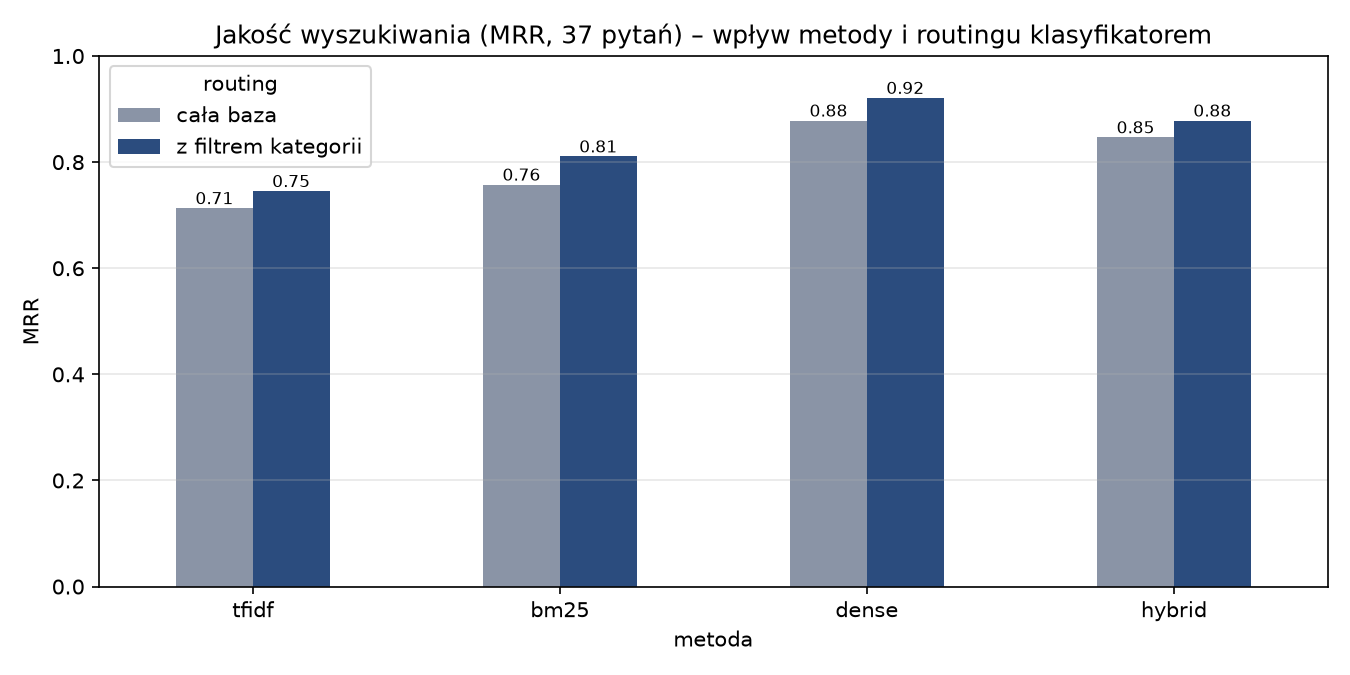

In [2]:
ret = pd.read_csv(f"{R}/retrieval/retrieval_metrics.csv")
display(ret.round(3)); display(Image(f"{R}/retrieval/retrieval_mrr.png", width=700))

## 2. QA: ablacja i porównanie z modelami z laboratoriów

,wariant,token_f1,rougeL,bertscore_f1,faithfulness,correctness,trafienie_zrodla,odmowa_poprawna
0,llm_bez_rag,0.262,0.210,0.712,1.892,2.000,NaN,0.0
1,flan_t5,0.071,0.067,0.495,NaN,NaN,NaN,0.0
2,extractive_xlmr,0.194,0.187,0.647,3.892,2.459,NaN,0.0
3,rag_bez_klasyfikatora,0.365,0.324,0.741,4.595,4.730,1.000,1.0
4,pelny_pipeline,0.366,0.330,0.739,4.892,4.730,0.973,1.0


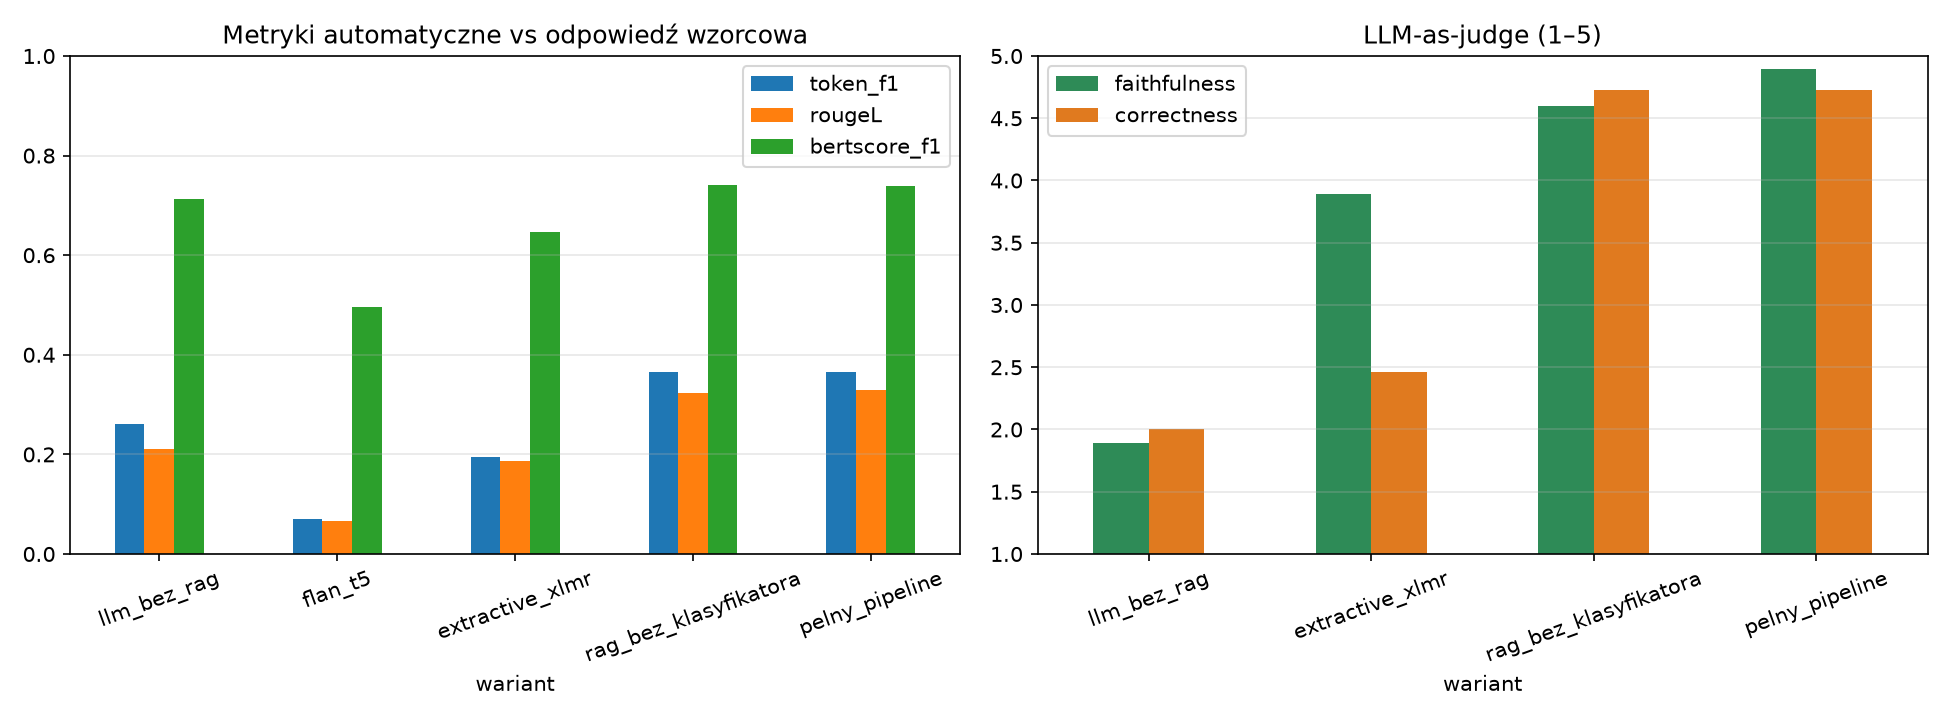

In [3]:
qa = pd.read_csv(f"{R}/qa/qa_summary.csv"); display(qa)
display(Image(f"{R}/qa/qa_ablacja.png", width=900))

## 3. Przykłady: to samo pytanie, różne warianty

In [4]:
det = pd.read_csv(f"{R}/qa/qa_details.csv")
for qid in ["Q11", "Q30", "Q18"]:
    sub = det[det.id == qid]
    print("=" * 100); print(sub.pytanie.iloc[0]); print("WZORZEC:", sub.referencja.iloc[0]); print()
    for _, r in sub.iterrows():
        print(f"[{r.wariant}] (F={r.get('faithfulness')}, C={r.get('correctness')})\n   {str(r.odpowiedz)[:400]}\n")

Co się stanie, jeśli spóźnię się z płatnością w Zapłać później?
WZORZEC: Po przekroczeniu 30-dniowego terminu partner usługi nalicza opłatę 9,99 zł za każde 14 dni opóźnienia.

[pelny_pipeline] (F=5.0, C=5.0)
   Jeśli przekroczysz termin płatności w usłudze „Zapłać później”, partner usługi naliczy opłatę w wysokości 9,99 zł za każde 14 dni opóźnienia [3]. Usługa ta jest dostępna dla zalogowanych klientów przy zamówieniach do 3000 zł i pozwala na zapłacenie za towar w ciągu 30 dni bez dodatkowych kosztów (jeśli termin zostanie dotrzymany) [1, 3]. Warto pamiętać, że termin płatności jest kluczowy dla unikni

[rag_bez_klasyfikatora] (F=5.0, C=5.0)
   Jeśli przekroczysz termin płatności w usłudze „Zapłać później”, partner usługi naliczy opłatę w wysokości 9,99 zł za każde 14 dni opóźnienia [3]. Usługa ta pozwala na opłacenie zamówienia do 3000 zł w ciągu 30 dni bez dodatkowych kosztów, pod warunkiem posiadania konta w sklepie [1, 3]. Warto pamiętać, że termin płatności jest kluczowy dla un

## 4. Gdzie pełny pipeline się myli?

In [5]:
full = det[(det.wariant == "pelny_pipeline") & (det.kategoria != "poza_zakresem")]
full.sort_values("correctness")[["id", "pytanie", "odpowiedz", "correctness", "faithfulness", "trafienie_zrodla"]].head(6)

,id,pytanie,odpowiedz,correctness,faithfulness,trafienie_zrodla
85,Q18,Co muszę zrobić z telefonem przed odesłaniem go w ramach zwrotu?,"Przed odesłaniem telefonu prosimy o odpowiednie zabezpieczenie towaru (wiedza ogólna). Należy zapakować produkt tak, aby nie uległ uszkodzeniu w transporcie...",1.0,5.0,1.0
30,Q07,"Nie odebrałem paczki z paczkomatu w terminie, co się stanie z pieniędzmi?","Jeśli nie odbierzesz paczki z paczkomatu w wyznaczonym czasie, zamówienie zostanie anulowane, a opłata zostanie Ci zwrócona [1]. Paczka w takim przypadku wr...",3.0,4.0,1.0
140,Q29,Dostałem SMS o dopłacie do przesyłki z linkiem. Czy to od was?,Dzień dobry! Po nadaniu paczki wysyłamy SMS oraz e-mail zawierający numer przesyłki i link do śledzenia [1]. Jeśli jednak otrzymałeś wiadomość o koniecznośc...,3.0,5.0,0.0
70,Q15,ile mam czasu na zwrot butow... znaczy sluchawek kupionych online,"Zakupione przez internet słuchawki możesz zwrócić bez podania przyczyny w ciągu 30 dni od ich doręczenia [1, 3]. Jeśli Twoje zamówienie zostało dostarczone ...",3.0,5.0,1.0
15,Q04,Jaki maksymalny gabaryt paczki zmieści się w paczkomacie?,"Maksymalny gabaryt paczki, która może zostać dostarczona do paczkomatu, to 41 × 38 × 64 cm [2]. Dodatkowo przesyłka nie może przekraczać wagi 25 kg [2].",5.0,5.0,1.0
20,Q05,Czy kurier podłączy mi nową pralkę do wody?,"Nie, usługa dostawy dużego sprzętu z wniesieniem nie obejmuje podłączenia urządzenia do instalacji wodnej ani gazowej [1]. Kurier jest odpowiedzialny jedyni...",5.0,4.0,1.0


## 5. Pytania poza zakresem

In [6]:
det[det.kategoria == "poza_zakresem"][["pytanie", "wariant", "odmowa_poprawna", "odpowiedz"]]

,pytanie,wariant,odmowa_poprawna,odpowiedz
185,Jaka jest stolica Australii?,pelny_pipeline,1.0,"Jestem asystentem obsługi klienta sklepu Zorza Elektronika i mogę pomóc w sprawach zamówień, płatności, dostawy, zwrotów i reklamacji, konta oraz gwarancji...."
186,Jaka jest stolica Australii?,rag_bez_klasyfikatora,1.0,"Przepraszam, ale nie posiadam informacji na temat stolicy Australii w naszych źródłach danych. Jeśli potrzebujesz pomocy w innych kwestiach dotyczących skle..."
187,Jaka jest stolica Australii?,llm_bez_rag,0.0,Stolicą Australii jest Canberra. W czym mogę jeszcze pomóc w związku z naszym sklepem?
188,Jaka jest stolica Australii?,extractive_xlmr,0.0,złotych polskich
189,Jaka jest stolica Australii?,flan_t5,0.0,Zorza Elektronik sp. z o.o. z siedzib przy ul. K
190,Napisz mi przepis na sernik.,pelny_pipeline,1.0,"Jestem asystentem obsługi klienta sklepu Zorza Elektronika i mogę pomóc w sprawach zamówień, płatności, dostawy, zwrotów i reklamacji, konta oraz gwarancji...."
191,Napisz mi przepis na sernik.,rag_bez_klasyfikatora,1.0,"Przepraszam, ale nie posiadam informacji dotyczących przepisów kulinarnych w naszych źródłach. (wiedza ogólna) Jako konsultant sklepu Zorza Elektronika poma..."
192,Napisz mi przepis na sernik.,llm_bez_rag,0.0,"Przepraszam, ale jako konsultant sklepu Zorza Elektronika zajmuję się wyłącznie obsługą zamówień, pytaniami dotyczącymi produktów elektronicznych oraz kwest..."
193,Napisz mi przepis na sernik.,extractive_xlmr,0.0,Domyślnie wysyłamy zamówienie w jednej paczce
194,Napisz mi przepis na sernik.,flan_t5,0.0,if any products are present


## Wnioski: synergia komponentów
* **Retrieval:** wyszukiwanie semantyczne (bge-m3) bije metody leksykalne (MRR 0.88 vs 0.71-0.76), bo rozumie
  parafrazy i potoczne sformułowania. Hybryda RRF ma najlepszy Recall@3/@4 (1.00 bez filtra), w RAG liczy się,
  by właściwy fragment był *gdziekolwiek* w kontekście, dlatego jest domyślną metodą.
* **Routing klasyfikatorem** podnosi MRR każdej metody o 0.03-0.05: mniej konkurencyjnych wpisów z innych kategorii.
  Koszt: przy błędnej klasyfikacji filtr może odciąć właściwy wpis (hybryda: Recall@4 1.00 → 0.97).
* **RAG vs sam LLM:** bez dokumentów model płynnie zmyśla zasady sklepu (faithfulness 1.9/5, correctness 2.0/5)
 : to te same halucynacje, które badaliśmy w Lab 5. Z RAG: 4.6-4.9 / 4.7.
* **Klasyfikator w pipeline'ie** zwiększa ugruntowanie odpowiedzi (faithfulness 4.60 → 4.89) i pozwala odmawiać
  na pytania spoza zakresu bez wywołania LLM.
* **Metryki automatyczne:** BERTScore prawie nie odróżnia halucynacji od poprawnej odpowiedzi (0.71 vs 0.74),
  a ROUGE/Token-F1 karzą poprawne odpowiedzi sformułowane innymi słowami (Lab 4). Ocena ugruntowania
  (LLM-as-judge) lepiej oddaje jakość RAG, z zastrzeżeniem, że oceniający model jest tym samym, który odpowiada.
* **Modele z laboratoriów:** FLAN-T5 (angielski) i extractive QA nie radzą sobie z polskimi pytaniami wymagającymi
  łączenia faktów lub obliczeń (np. 15% z 4000 zł), uzasadnia to użycie lokalnego LLM jako generatora.